# Financial Time-Series Forecasting: SPY Weekly Returns

**Author: Umer Farooq**

## 1. Data Acquisition

In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

# 1. Download daily SPY data using Ticker().history()
print("Downloading SPY data...")
spy = yf.Ticker('SPY')
# .history() automatically adjusts for splits and dividends in its 'Close' column
spy_daily = spy.history(start='2005-01-01', end='2025-12-31')

# 2. Keep only the Close price (which is adjusted)
df = spy_daily[['Close']].copy()
df.columns = ['adj_close']

# 3. Resample to weekly frequency (using Friday's close)
df_weekly = df.resample('W-FRI').last()
print(f"Weekly observations: {len(df_weekly)}")


Weekly observations: 1096


## 2. Feature Engineering & Preventing Data Leakage

In [2]:
# 1-week return (our base momentum feature)
df_weekly['lag_return_1w'] = df_weekly['adj_close'].pct_change(1)

# 4-week cumulative return (medium-term momentum)
df_weekly['lag_return_4w'] = df_weekly['adj_close'].pct_change(4)

# 13-week rolling volatility (standard deviation of the 1-week returns)
df_weekly['volatility_13w'] = df_weekly['lag_return_1w'].rolling(window=13).std()



In [3]:
# The Target: Shift the 1-week return backward by 1 row
df_weekly['target_return_1w'] = df_weekly['lag_return_1w'].shift(-1)

# Define the Volatility Regime
# To avoid data leakage, we use an expanding median (only looking at past data), 
# rather than the median of the entire 20-year dataset.
expanding_median = df_weekly['volatility_13w'].expanding().median()
df_weekly['volatility_regime'] = np.where(
    df_weekly['volatility_13w'] > expanding_median, 'High', 'Low'
)

# Drop missing values created by our rolling windows and shifts
df_clean = df_weekly.dropna().copy()

print(f"Clean observations ready for modeling: {len(df_clean)}")
df_clean[['adj_close', 'lag_return_1w', 'volatility_13w', 'volatility_regime', 'target_return_1w']].tail()

Clean observations ready for modeling: 1082


,adj_close,lag_return_1w,volatility_13w,volatility_regime,target_return_1w
Date,,,,,
2025-11-28 00:00:00-05:00,676.095886,0.036963,0.017222,Low,0.003365
2025-12-05 00:00:00-05:00,678.371277,0.003365,0.017222,Low,-0.005731
2025-12-12 00:00:00-05:00,674.483276,-0.005731,0.017116,Low,0.001234
2025-12-19 00:00:00-05:00,675.315369,0.001234,0.016894,Low,0.014282
2025-12-26 00:00:00-05:00,684.959961,0.014282,0.017126,Low,-0.004780


## 3. Chronological Data Splitting

In [4]:
# Split the data sequentially
train = df_clean.loc['2005-01-01':'2017-12-31']
val = df_clean.loc['2018-01-01':'2021-12-31']
test = df_clean.loc['2022-01-01':'2025-12-31']

print(f"Training set: {len(train)} weeks")
print(f"Validation set: {len(val)} weeks")
print(f"Test set: {len(test)} weeks")

Training set: 665 weeks
Validation set: 209 weeks
Test set: 208 weeks


In [5]:
from sklearn.metrics import mean_absolute_error, mean_squared_error


def evaluate_forecast(y_true, y_pred, model_name="Model"):
    """
    Calculates and prints MAE, RMSE, and Directional Accuracy.
    Returns a dictionary of the results.
    """
    # 1. Error Metrics
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    
    # 2. Directional Accuracy
    # np.sign() converts returns to 1 (positive), -1 (negative), or 0 (flat)
    true_direction = np.sign(y_true)
    pred_direction = np.sign(y_pred)
    
    # Calculate the percentage of time the model guessed the correct direction
    dir_acc = np.mean(true_direction == pred_direction) * 100
    
    print(f"--- {model_name} ---")
    print(f"MAE:                  {mae:.4f}")
    print(f"RMSE:                 {rmse:.4f}")
    print(f"Directional Accuracy: {dir_acc:.2f}%\n")
    
    return {'Model': model_name, 'MAE': mae, 'RMSE': rmse, 'Dir_Acc': dir_acc}

# Create a list to store our results so we can build a comparison table later
results_list = []

## 4. Establishing Naive Benchmarks.

In [6]:
# Predict exactly 0.0 for every week in the Validation and Test sets
val_zero_preds = np.zeros(len(val))
test_zero_preds = np.zeros(len(test))

# Evaluate on the Test set (we usually report final numbers on the Test set)
res_zero = evaluate_forecast(
    y_true=test['target_return_1w'], 
    y_pred=test_zero_preds, 
    model_name="Zero-Return Benchmark"
)
results_list.append(res_zero)

--- Zero-Return Benchmark ---
MAE:                  0.0181
RMSE:                 0.0237
Directional Accuracy: 0.00%



##  Establishing Naive Benchmarks.

In [7]:
# Calculate the average weekly return from the Training set ONLY
train_mean_return = train['target_return_1w'].mean()
print(f"Historical Mean (Train): {train_mean_return:.4f} ({train_mean_return*100:.2f}% per week)\n")

# Predict this exact average for every week in the Validation and Test sets
val_mean_preds = np.full(len(val), train_mean_return)
test_mean_preds = np.full(len(test), train_mean_return)

# Evaluate on the Test set
res_mean = evaluate_forecast(
    y_true=test['target_return_1w'], 
    y_pred=test_mean_preds, 
    model_name="Historical-Mean Benchmark"
)
results_list.append(res_mean)

Historical Mean (Train): 0.0019 (0.19% per week)

--- Historical-Mean Benchmark ---
MAE:                  0.0179
RMSE:                 0.0236
Directional Accuracy: 54.81%



In [8]:
from sklearn.ensemble import RandomForestRegressor

# 1. Isolate the features (X) and target (y)
features = ['lag_return_1w', 'lag_return_4w', 'volatility_13w']
target = 'target_return_1w'

X_train = train[features]
y_train = train[target]

X_test = test[features]
y_test = test[target]

# 2. Initialize the Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,      # Number of trees to build
    max_depth=3,           # Restrict tree depth to prevent overfitting the noise
    min_samples_leaf=10,   # Require at least 10 weeks of data in every final node
    random_state=42        # Ensures your results are exactly reproducible for the paper
)

# 3. Train the model using the chronological training set
print("Training Random Forest...")
rf_model.fit(X_train, y_train)

# 4. Generate predictions for the Test set
test_rf_preds = rf_model.predict(X_test)

# 5. Evaluate the predictions using our standardized function
res_rf = evaluate_forecast(
    y_true=y_test, 
    y_pred=test_rf_preds, 
    model_name="Random Forest"
)
results_list.append(res_rf)

Training Random Forest...
--- Random Forest ---
MAE:                  0.0180
RMSE:                 0.0238
Directional Accuracy: 53.85%



In [9]:
# Convert the results list into a clean pandas DataFrame for the paper
results_df = pd.DataFrame(results_list)
results_df.set_index('Model', inplace=True)

print("--- OVERALL TEST SET PERFORMANCE ---")
display(results_df.round(4))

--- OVERALL TEST SET PERFORMANCE ---


,MAE,RMSE,Dir_Acc
Model,,,
Zero-Return Benchmark,0.0181,0.0237,0.0000
Historical-Mean Benchmark,0.0179,0.0236,54.8077
Random Forest,0.0180,0.0238,53.8462


In [10]:
# Create a list to store regime-specific results
regime_results = []

# Loop through both regimes to avoid writing the code twice
for regime in ['Low', 'High']:
    print(f"========== VOLATILITY REGIME: {regime.upper()} ==========")
    
    # 1. Create a boolean mask to filter rows for the current regime
    mask = test['volatility_regime'] == regime
    
    # 2. Isolate the actual target returns for these specific weeks
    y_test_regime = y_test[mask]
    
    print(f"Number of weeks in {regime} regime: {len(y_test_regime)}\n")
    
    # Only proceed if we actually have data for this regime in the test set
    if len(y_test_regime) > 0:
        
        # 3. Filter our previously generated prediction arrays using the exact same mask
        # This ensures the predictions match perfectly with the actual returns
        zero_preds_regime = test_zero_preds[mask]
        mean_preds_regime = test_mean_preds[mask]
        rf_preds_regime = test_rf_preds[mask]
        
        # 4. Evaluate each model on this specific subset
        res_zero = evaluate_forecast(y_test_regime, zero_preds_regime, "Zero-Return")
        res_mean = evaluate_forecast(y_test_regime, mean_preds_regime, "Historical-Mean")
        res_rf = evaluate_forecast(y_test_regime, rf_preds_regime, "Random Forest")
        
        # Add a 'Regime' label to our dictionaries before storing them
        res_zero['Regime'] = regime
        res_mean['Regime'] = regime
        res_rf['Regime'] = regime
        
        regime_results.extend([res_zero, res_mean, res_rf])

# Display a clean summary table grouped by regime
regime_df = pd.DataFrame(regime_results)
regime_df = regime_df.set_index(['Regime', 'Model'])
display(regime_df.round(4))

========== VOLATILITY REGIME: LOW ==========
Number of weeks in Low regime: 81

--- Zero-Return ---
MAE:                  0.0154
RMSE:                 0.0206
Directional Accuracy: 0.00%

--- Historical-Mean ---
MAE:                  0.0153
RMSE:                 0.0207
Directional Accuracy: 54.32%

--- Random Forest ---
MAE:                  0.0154
RMSE:                 0.0209
Directional Accuracy: 54.32%

========== VOLATILITY REGIME: HIGH ==========
Number of weeks in High regime: 127

--- Zero-Return ---
MAE:                  0.0198
RMSE:                 0.0255
Directional Accuracy: 0.00%

--- Historical-Mean ---
MAE:                  0.0196
RMSE:                 0.0253
Directional Accuracy: 55.12%

--- Random Forest ---
MAE:                  0.0196
RMSE:                 0.0255
Directional Accuracy: 53.54%



MAE    RMSE  Dir_Acc
Regime Model                                   
Low    Zero-Return      0.0154  0.0206   0.0000
       Historical-Mean  0.0153  0.0207  54.3210
       Random Forest    0.0154  0.0209  54.3210
High   Zero-Return      0.0198  0.0255   0.0000
       Historical-Mean  0.0196  0.0253  55.1181
       Random Forest    0.0196  0.0255  53.5433

## 5. Machine Learning Evaluation (Random Forest)

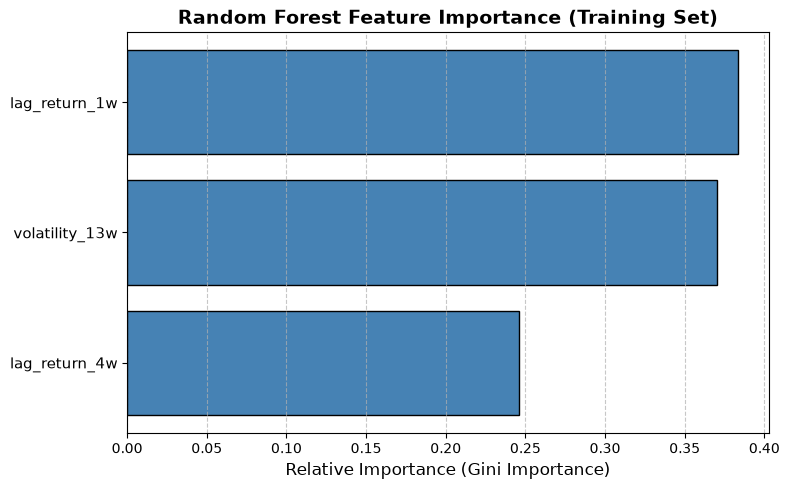

In [11]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Extract the feature importance scores from our trained Random Forest
importances = rf_model.feature_importances_
feature_names = X_train.columns

# 2. Sort the features from least to most important
indices = np.argsort(importances)

# 3. Create a horizontal bar chart
plt.figure(figsize=(8, 5))
plt.barh(range(len(indices)), importances[indices], color='steelblue', edgecolor='black')
plt.yticks(range(len(indices)), [feature_names[i] for i in indices], fontsize=11)
plt.title("Random Forest Feature Importance (Training Set)", fontsize=14, fontweight='bold')
plt.xlabel("Relative Importance (Gini Importance)", fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
# Save the figure 
plt.savefig('feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()

## 6. Performance Across Volatility Regimes

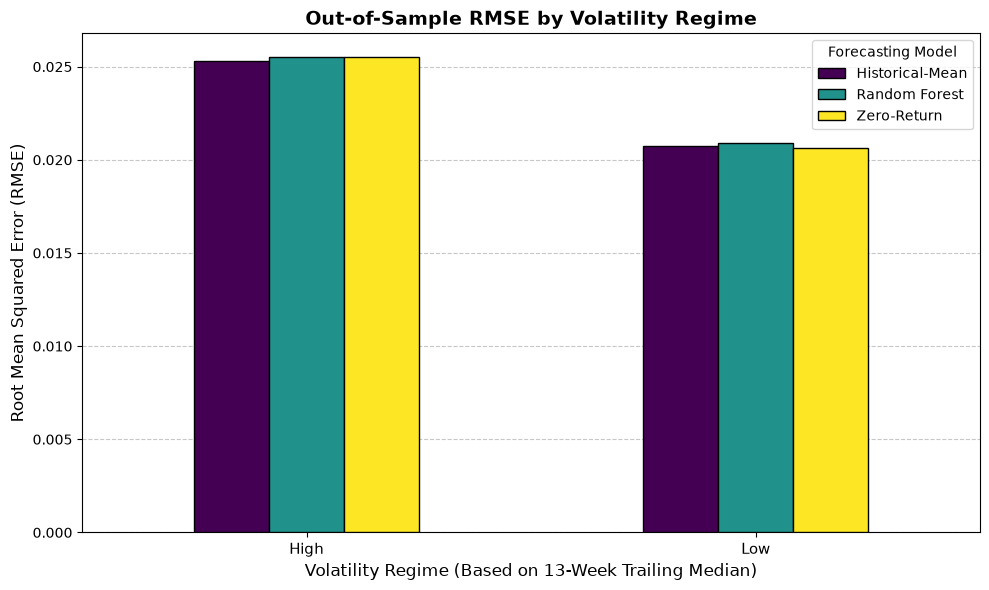

In [12]:
# 1. Extract just the RMSE column from our regime_df and unstack it for grouped plotting
# (Ensure you ran the previous regime evaluation cell so regime_df is loaded)
rmse_unstacked = regime_df['RMSE'].unstack()

# 2. Plot a grouped bar chart
ax = rmse_unstacked.plot(kind='bar', figsize=(10, 6), colormap='viridis', edgecolor='black', zorder=3)

plt.title('Out-of-Sample RMSE by Volatility Regime', fontsize=14, fontweight='bold')
plt.ylabel('Root Mean Squared Error (RMSE)', fontsize=12)
plt.xlabel('Volatility Regime (Based on 13-Week Trailing Median)', fontsize=12)
plt.xticks(rotation=0, fontsize=11)
plt.legend(title='Forecasting Model', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7, zorder=0)
plt.tight_layout()
plt.savefig('rmse_by_regime.png', dpi=300, bbox_inches='tight')
plt.show()

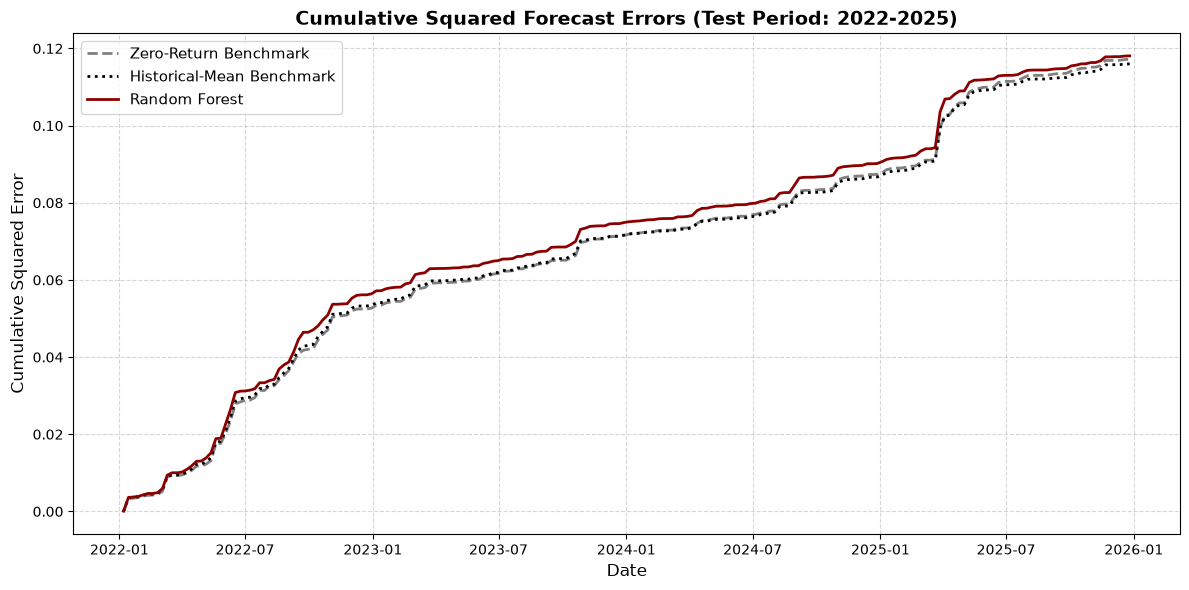

In [13]:
# 1. Calculate the squared error for every single week in the test set
se_zero = (y_test - test_zero_preds) ** 2
se_mean = (y_test - test_mean_preds) ** 2
se_rf = (y_test - test_rf_preds) ** 2

# 2. Calculate the cumulative sum of these errors over time
cse_zero = se_zero.cumsum()
cse_mean = se_mean.cumsum()
cse_rf = se_rf.cumsum()

# 3. Plot the time series
plt.figure(figsize=(12, 6))
plt.plot(cse_zero.index, cse_zero, label="Zero-Return Benchmark", linestyle='--', color='gray', linewidth=2)
plt.plot(cse_mean.index, cse_mean, label="Historical-Mean Benchmark", linestyle=':', color='black', linewidth=2)
plt.plot(cse_rf.index, cse_rf, label="Random Forest", color='darkred', linewidth=2)

plt.title('Cumulative Squared Forecast Errors (Test Period: 2022-2025)', fontsize=14, fontweight='bold')
plt.ylabel('Cumulative Squared Error', fontsize=12)
plt.xlabel('Date', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('cumulative_errors.png', dpi=300, bbox_inches='tight')
plt.show()

In [14]:
import numpy as np
from scipy import stats

def dm_test_1step(y_true, pred_1, pred_2, criterion='MSE'):
    """
    Performs a 1-step ahead Diebold-Mariano test.
    pred_1: Baseline predictions
    pred_2: Challenger predictions (e.g., Random Forest)
    Returns the DM statistic and the p-value.
    """
    # 1. Calculate the forecast errors
    e1 = y_true - pred_1
    e2 = y_true - pred_2
    
    # 2. Calculate the loss differential (squared error or absolute error)
    if criterion == 'MSE':
        d = (e1 ** 2) - (e2 ** 2)
    elif criterion == 'MAE':
        d = np.abs(e1) - np.abs(e2)
    else:
        raise ValueError("Criterion must be 'MSE' or 'MAE'")
    
    # 3. Perform a 1-sample t-test to see if the mean of the differential is 0
    # The DM statistic for h=1 is mathematically equivalent to the t-statistic
    mean_d = np.mean(d)
    dm_stat, p_value = stats.ttest_1samp(d, popmean=0.0)
    
    # Return results
    return dm_stat, p_value, mean_d

In [15]:
# Test 1: Random Forest vs. Zero-Return Benchmark
dm_stat_zero, p_val_zero, mean_d_zero = dm_test_1step(
    y_test, test_zero_preds, test_rf_preds, criterion='MSE'
)

# Test 2: Random Forest vs. Historical-Mean Benchmark
dm_stat_mean, p_val_mean, mean_d_mean = dm_test_1step(
    y_test, test_mean_preds, test_rf_preds, criterion='MSE'
)

print("--- DIEBOLD-MARIANO TEST RESULTS (Overall Test Set) ---")
print("Null Hypothesis: Models have equal predictive accuracy.\n")

print("1. Random Forest vs. Zero-Return:")
print(f"   DM Statistic: {dm_stat_zero:.4f}")
print(f"   P-value:      {p_val_zero:.4f}")
if p_val_zero < 0.05:
    print("   Result:       Significant difference in accuracy (Reject Null)")
else:
    print("   Result:       No significant difference (Fail to Reject Null)")

print("\n2. Random Forest vs. Historical-Mean:")
print(f"   DM Statistic: {dm_stat_mean:.4f}")
print(f"   P-value:      {p_val_mean:.4f}")
if p_val_mean < 0.05:
    print("   Result:       Significant difference in accuracy (Reject Null)")
else:
    print("   Result:       No significant difference (Fail to Reject Null)")

--- DIEBOLD-MARIANO TEST RESULTS (Overall Test Set) ---
Null Hypothesis: Models have equal predictive accuracy.

1. Random Forest vs. Zero-Return:
   DM Statistic: -0.2454
   P-value:      0.8064
   Result:       No significant difference (Fail to Reject Null)

2. Random Forest vs. Historical-Mean:
   DM Statistic: -0.7146
   P-value:      0.4757
   Result:       No significant difference (Fail to Reject Null)
